# 01 · Validação dos dados brutos

A Olist conecta lojas pequenas aos grandes marketplaces brasileiros. A base pública traz cerca de 100 mil pedidos de 2016 a 2018, divididos em 9 tabelas: pedidos, itens, pagamentos, avaliações, clientes, produtos, vendedores, geolocalização e tradução de categorias.

Antes de calcular qualquer indicador, valido como os dados chegaram. Cada etapa registra a hipótese, o teste usado e o que o resultado sustenta.

Começo pela tabela de **pedidos** (`orders`), que é o centro do modelo: as demais tabelas se ligam a ela pelo `order_id`.

## 1.1 Leitura da tabela de pedidos

Carrego o arquivo com `pd.read_csv()` e uso `.shape` para conferir o volume com o que o enunciado descreve (cerca de 100 mil pedidos). Também importo o `matplotlib`, que uso nos gráficos, e defino um estilo único para todos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#a3a29d'
plt.rcParams.update({
    'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#a3a29d', 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.grid.axis': 'y',
})

orders = pd.read_csv('../data/raw/olist_orders_dataset.csv')
orders.shape

(99441, 8)

**99.441 linhas e 8 colunas**, coerente com o enunciado. O volume não indica arquivo incompleto.

## 1.2 Primeiras e últimas linhas

Com `.head()` e `.tail()` confiro o formato dos registros e se o fim do arquivo traz totais ou rodapé, comuns em extrações.

In [2]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
orders.tail()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00
99440,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00


- O fim do arquivo segue o mesmo padrão do início: sem totais nem rodapé.
- Os ids são códigos embaralhados, efeito da anonimização.
- As linhas não seguem ordem de data (a 1ª é de out/2017, a 2ª de jul/2018).
- As 5 datas parecem descrever a jornada do pedido: **compra → aprovação do pagamento → entrega à transportadora → entrega ao cliente**, além da **data prometida**.
- Nas 10 linhas, a data prometida (`order_estimated_delivery_date`) sempre termina em `00:00:00`. **Hipótese:** a promessa é feita só em dia, sem hora. Isso pesa quando eu comparar entrega e promessa.

## 1.3 Preenchimento das colunas

Uso `.info()` para ver tipo e quantidade de valores preenchidos (`Non-Null Count`) por coluna.

In [4]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


- Cinco colunas têm 99.441 valores, mas `order_approved_at`, `order_delivered_carrier_date` e `order_delivered_customer_date` têm menos. **Existem valores vazios**, todos em datas da jornada.
- As datas estão como texto (`str`). Antes de calcular prazos, vou precisar convertê-las.

## 1.4 Unicidade dos pedidos

Para testar a hipótese de que cada linha é um pedido diferente, uso `.describe()`. Em colunas de texto ele traz `count` (preenchidos), `unique` (distintos), `top` (valor mais frequente) e `freq` (vezes que ele aparece). Se `count` e `unique` de `order_id` forem iguais, não há pedido repetido.

In [5]:
orders.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


- `order_id`: `count` = `unique` = 99.441. **Cada linha é um pedido diferente**, e o `order_id` serve como chave primária.
- `customer_id` também tem 99.441 valores distintos: nenhum cliente aparece em dois pedidos. Em dois anos de operação, isso é improvável. **Hipótese:** o `customer_id` é gerado a cada pedido e não identifica a pessoa. Testo quando abrir a tabela de clientes.
- `order_status` tem 8 valores; o mais frequente é `delivered`, com 96.478 pedidos (97%).
- `order_estimated_delivery_date` tem só **459 valores distintos**, contra 98.875 da data de compra, que tem hora, minuto e segundo. Se a promessa tivesse hora, os valores seriam quase todos diferentes; 459 é compatível com um valor por dia. O `top` (`2017-12-20 00:00:00`, 522 pedidos) também está sem hora. Isso reforça a hipótese de que a promessa é só o dia, mas o `describe` mostra um único valor. Ainda preciso testar todas as linhas.

## 1.5 Valores nulos

Para quantificar os vazios, uso `.isnull()` somado por coluna: cada vazio vira 1 (`True`) e cada preenchido vira 0 (`False`), então a soma entrega a quantidade de nulos.

In [6]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Os vazios estão só em três datas da jornada. Para ver a relação entre elas, coloco as três num gráfico de barras com `plt.bar()`, na ordem em que as etapas acontecem.

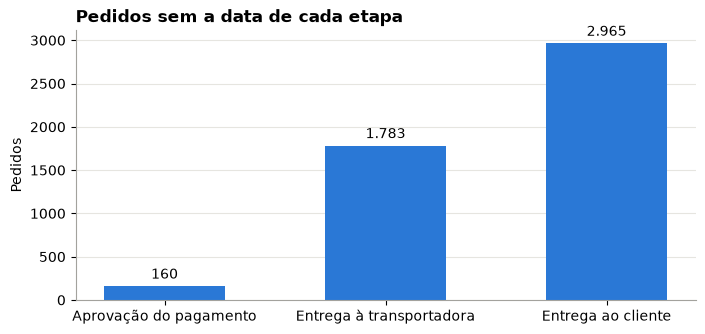

In [7]:
etapas = {'Aprovação do pagamento': 'order_approved_at',
          'Entrega à transportadora': 'order_delivered_carrier_date',
          'Entrega ao cliente': 'order_delivered_customer_date'}
vazios = [orders[coluna].isnull().sum() for coluna in etapas.values()]

plt.figure(figsize=(8, 3.5))
barras = plt.bar(list(etapas.keys()), vazios, color=AZUL, width=0.55)
plt.bar_label(barras, labels=[f'{v:,}'.replace(',', '.') for v in vazios], padding=3)
plt.title('Pedidos sem a data de cada etapa')
plt.ylabel('Pedidos')
plt.show()

Os vazios **aumentam a cada etapa da jornada** (160, 1.783 e 2.965), como um funil. Duas hipóteses:

- **H1, processo não concluído:** o pedido não chegou a essa etapa (cancelado ou ainda em andamento). O vazio é esperado.
- **H2, falha de registro:** o pedido passou pela etapa, mas a data não foi gravada. O vazio é erro.

Se a H1 explicar tudo, os vazios estarão só nos pedidos que não foram entregues. Vazio em pedido `delivered` indica H2.

## 1.6 Teste das hipóteses: vazios por status

Para separar as duas hipóteses, cruzo os vazios das três datas com o status do pedido: `.isnull()` marca os vazios e `.groupby(order_status).sum()` totaliza por status, como uma tabela dinâmica. Acrescento o total de pedidos de cada status (`.value_counts()`) para comparar.

In [8]:
datas_com_vazio = ['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']

vazios_por_status = orders[datas_com_vazio].isnull().groupby(orders['order_status']).sum()
vazios_por_status['total_pedidos'] = orders['order_status'].value_counts()
vazios_por_status

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,total_pedidos
order_status,,,,
approved,0,2,2,2
canceled,141,550,619,625
created,5,5,5,5
delivered,14,2,8,96478
invoiced,0,314,314,314
processing,0,301,301,301
shipped,0,0,1107,1107
unavailable,0,609,609,609


**A H1 explica a maior parte dos vazios.** Cada status para na etapa esperada:
- `shipped` (enviado): os 1.107 têm data de postagem e nenhum tem data de entrega. Estão a caminho.
- `approved`, `invoiced` e `processing` (aprovado, faturado e em separação): sem postagem e sem entrega. Ainda não saíram do vendedor.
- `unavailable` (indisponível): também param antes da postagem.
- `created` (criado): 5 pedidos sem nenhuma data além da compra.

**A H2 aparece em poucos casos.** Entre os 96.478 pedidos entregues, 14 não têm data de aprovação, 2 não têm data de postagem e 8 não têm data de entrega. São 24 falhas de registro (0,02% dos entregues).

**Os cancelados não se comportam como esperado.** Dos 625, só 619 estão sem data de entrega: **6 cancelados têm data de entrega** e 75 têm data de postagem. Hipótese: cancelamento depois da saída do vendedor (devolução ou cancelamento tardio).

**Decisão:** prazo de entrega será medido só com pedidos `delivered` que tenham data de entrega. Os 8 entregues sem essa data saem do cálculo. Os demais vazios descrevem pedidos que não terminaram a jornada e não são tratados como erro.

**Pergunta em aberto:** se as datas descrevem uma jornada, elas deveriam estar em ordem (compra, aprovação, postagem, entrega). Isso vale para todos os pedidos?

## 1.7 Pedidos não concluídos: em andamento ou travados?

A H1 explicou os vazios como pedidos "cancelados ou ainda em andamento". Ao olhar os pedidos parados (`created`, `approved`, `processing`, `invoiced`, `shipped`), aparecem compras de 2016, numa base que vai até 2018. Isso não derruba a H1, porque o processo continua não concluído, mas questiona a parte "em andamento": um pedido pode ter parado por erro, abandono ou falta de atualização do status.

Para separar os dois casos, uso a **data prometida** de cada pedido. Se, no último registro da base, a promessa ainda não venceu, o pedido pode estar a caminho. Se já venceu, ele está travado.

Para comparar datas, converto as colunas de texto com `pd.to_datetime()`. A "data da foto" é o evento mais recente registrado (compra, aprovação, postagem ou entrega). A data prometida fica de fora porque é uma previsão, não um evento ocorrido.

In [9]:
colunas_data = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                'order_delivered_customer_date', 'order_estimated_delivery_date']
for coluna in colunas_data:
    orders[coluna] = pd.to_datetime(orders[coluna])

eventos = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']
data_foto = orders[eventos].max().max()
print('Último evento registrado na base:', data_foto)

parados = orders[orders['order_status'].isin(['created', 'approved', 'processing', 'invoiced', 'shipped'])].copy()
parados['promessa_vencida'] = parados['order_estimated_delivery_date'] < data_foto
parados['dias_apos_promessa'] = (data_foto - parados['order_estimated_delivery_date']).dt.days

parados.groupby('order_status').agg(
    pedidos=('order_id', 'count'),
    promessa_vencida=('promessa_vencida', 'sum'),
    mediana_dias_apos_promessa=('dias_apos_promessa', 'median'),
)

Último evento registrado na base: 2018-10-17 17:30:18


,pedidos,promessa_vencida,mediana_dias_apos_promessa
order_status,,,
approved,2,2,554.0
created,5,5,282.0
invoiced,314,314,315.5
processing,301,301,366.0
shipped,1107,1107,254.0


- A foto da base é de **17/10/2018**.
- **Os 1.729 pedidos parados já passaram da data prometida.** Nenhum está dentro do prazo.
- A mediana é de **254 a 554 dias** depois da promessa, conforme o status. Os enviados (`shipped`), por exemplo, deveriam ter chegado há cerca de 8 meses.

**Leitura:** a H1 continua válida, porque os vazios são de pedidos que não concluíram a jornada. O que muda é o motivo: **nenhum dos 1.729 pedidos parados no meio do fluxo está em andamento; todos estão travados.** A base é uma foto, e esses pedidos ficaram parados no status em que estavam.

Alcance do teste: dos 2.980 pedidos com alguma data vazia, ficaram de fora os cancelados (619) e os indisponíveis (609), cujo processo terminou por uma saída, e os entregues com data faltando (23), já explicados como falha de registro.

Os dados não dizem por que travaram. Hipóteses possíveis: extravio, cancelamento não registrado ou status que nunca foi atualizado. Outras tabelas (pagamentos, avaliações) podem trazer pistas.

Para a análise, esses 1.729 pedidos (1,7% da base) não entram no cálculo de prazo, porque não têm entrega. Para a receita, ainda preciso decidir se contam como venda.

## 1.8 Fluxo hipotético do pedido

Juntando o que os status e as datas mostraram, monto o fluxo provável de um pedido:

```
created ──► approved ──► processing ──► invoiced ──► shipped ──► delivered
(compra)    (pagamento   (validação     (nota        (postado)   (entregue)
             aprovado)    da nota?)      aceita)
   │            │              │            │           │
   └────────────┴──── canceled ┴────────────┴───────────┘  (sai em qualquer etapa)
                │
                └──► unavailable  (aprovado, mas não chega a ser postado)
```

O que cada parte tem a seu favor:

| Parte do fluxo | Evidência nos dados | Situação |
|---|---|---|
| `created` é o início | os 5 pedidos só têm data de compra | compatível (poucos casos) |
| `approved` vem após o pagamento | os 2 têm aprovação e nenhum tem postagem | compatível (poucos casos) |
| `processing` e `invoiced` vêm antes do envio | têm aprovação e nenhum tem postagem | compatível |
| `processing` vem antes de `invoiced` | nenhuma data separa os dois; o tempo até a aprovação é parecido | os dados não distinguem |
| `shipped` vem após a postagem | todos têm postagem e nenhum tem entrega | compatível |
| `unavailable` sai após a aprovação | todos têm aprovação e nenhum tem postagem | compatível |
| `canceled` sai em qualquer etapa | há cancelados sem aprovação (141), com postagem (75) e com entrega (6) | compatível |

"Compatível" significa que nenhum pedido contradiz a hipótese. Não é prova.

**Fonte externa:** o [guia de pedidos do portal de desenvolvedores da Olist](https://dev.olist.com/en/guides-and-tutorials/overview/orders) descreve a sequência **approved → invoice_processing → invoiced → shipped → delivered**. Nela, `invoice_processing` é a validação do XML da nota fiscal (etapa curta) e `invoiced` é a nota aceita, com os volumes de envio criados. Se o `processing` desta base equivale ao `invoice_processing`, ele vem **antes** do `invoiced` e trata da nota fiscal, não da separação do produto. É a melhor fonte disponível, com ressalvas:
- é a documentação atual da API para vendedores, não necessariamente o processo de 2016 a 2018;
- o nome é diferente (`invoice_processing` lá, `processing` aqui);
- ela não descreve `created`, `canceled` nem `unavailable`.

**Decisão:** adoto o fluxo acima como hipótese de trabalho. A ordem entre `processing` e `invoiced` segue a fonte oficial até que outra tabela confirme ou contradiga.

## 1.9 A data prometida tem hora?

A hipótese de que a promessa é feita só em dia veio de 10 linhas e do `describe`. Com as datas convertidas, testo todas as linhas: uso `.dt.hour`, `.dt.minute` e `.dt.second` para extrair hora, minuto e segundo, e verifico se os três são zero.

In [10]:
promessa = orders['order_estimated_delivery_date']
so_dia = (promessa.dt.hour == 0) & (promessa.dt.minute == 0) & (promessa.dt.second == 0)
so_dia.value_counts()

order_estimated_delivery_date
True    99441
Name: count, dtype: int64

Todas as 99.441 datas prometidas estão em `00:00:00`. **Hipótese confirmada: a promessa é só o dia.**

**Decisão:** ao comparar entrega e promessa, comparo dia com dia. Se eu comparar com horário, um pedido entregue às 15h do dia prometido apareceria como atrasado, porque 15h é depois de 00:00 daquele dia.

A hora da promessa não carrega informação, mas não a removo: no pandas, uma data com ou sem hora ocupa o mesmo espaço, e a comparação por dia resolve o problema.

## 1.10 As datas seguem a ordem da jornada?

Pelo fluxo do 1.8, cada pedido deveria ter compra ≤ aprovação ≤ postagem ≤ entrega. Para testar, comparo os pares de datas e conto os pedidos com **datas fora de ordem**, ou seja, uma etapa registrada antes da etapa que deveria vir primeiro. Quando uma das datas está vazia, a comparação dá `False`, então só entram pedidos com as duas datas preenchidas.

In [11]:
compra, aprov, postagem, entrega = (orders[c] for c in eventos)

fora_de_ordem = pd.Series({
    'aprovação antes da compra':   (aprov < compra).sum(),
    'postagem antes da compra':    (postagem < compra).sum(),
    'postagem antes da aprovação': (postagem < aprov).sum(),
    'entrega antes da compra':     (entrega < compra).sum(),
    'entrega antes da postagem':   (entrega < postagem).sum(),
})
fora_de_ordem

aprovação antes da compra         0
postagem antes da compra        166
postagem antes da aprovação    1359
entrega antes da compra           0
entrega antes da postagem        23
dtype: int64

- Compra é sempre a primeira data: nenhuma aprovação, postagem ou entrega vem antes dela, exceto **166 postagens**.
- **1.359 pedidos foram postados antes da aprovação do pagamento** (1,4% da base). As 166 postagens antes da compra estão dentro desse grupo.
- **23 pedidos foram entregues antes de serem postados.**

Todos os casos fora de ordem envolvem a **data de postagem**. Antes de decidir, vejo o tamanho dessas diferenças e o status desses pedidos.

In [12]:
algum_fora_de_ordem = (postagem < compra) | (postagem < aprov) | (entrega < postagem)
print('Pedidos com alguma data fora de ordem:', algum_fora_de_ordem.sum())

antes_da_compra = postagem < compra
print('Mediana da postagem antes da compra:', (compra - postagem)[antes_da_compra].median())

postou_antes = orders[postagem < aprov]
print(postou_antes['order_status'].value_counts())

(postou_antes['order_approved_at'] - postou_antes['order_delivered_carrier_date']).describe()

Pedidos com alguma data fora de ordem: 1382
Mediana da postagem antes da compra: 0 days 00:35:59.500000
order_status
delivered    1350
shipped         9
Name: count, dtype: int64


count                      1359
mean     1 days 00:45:07.153053
std      4 days 19:18:28.055754
min             0 days 00:00:21
25%      0 days 01:24:55.500000
50%             0 days 17:10:04
75%             1 days 01:57:24
max           171 days 05:15:22
dtype: object

- Somando os três tipos, **1.382 pedidos** têm alguma data fora de ordem.
- Quase todos (1.350) foram entregues normalmente. A data fora de ordem não impediu a jornada.
- A diferença mediana é de **17 horas**, e 25% ficam abaixo de 1h30. Há casos extremos, como 171 dias.

Diferenças pequenas e concentradas numa única coluna sugerem que o problema está **em como a data de postagem é registrada**, e não no processo. Duas hipóteses:

- **H3, registro manual:** a postagem é informada pelo vendedor ou pela transportadora, digitada ou ajustada à mão, e não gravada automaticamente pelo sistema.
- **H4, fuso horário:** o Brasil tem mais de um fuso. Se a postagem for registrada no horário local do vendedor e a compra no horário de Brasília, aparecem diferenças de 1 a 2 horas. A mediana de 36 minutos nas postagens "antes da compra" é compatível com isso.

Para a H3, uso uma pista simples. Um sistema que grava o horário automaticamente espalha os segundos entre 0 e 59, então só cerca de 1,7% (1 em 60) termina em `:00`. Uma data digitada ou registrada só com hora e minuto termina em `:00` com muito mais frequência. Comparo a proporção nas quatro datas de evento e mostro num gráfico de barras, com uma linha no 1,7% esperado.

order_purchase_timestamp          1.6
order_approved_at                 0.9
order_delivered_carrier_date     29.5
order_delivered_customer_date     1.6
dtype: float64


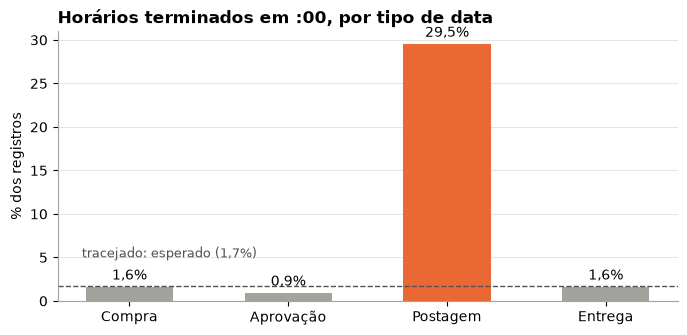

In [13]:
segundos_zerados = pd.Series({
    coluna: (orders[coluna].dropna().dt.second == 0).mean() * 100
    for coluna in eventos
}).round(1)
print(segundos_zerados)

nomes = ['Compra', 'Aprovação', 'Postagem', 'Entrega']
cores = [LARANJA if nome == 'Postagem' else CINZA for nome in nomes]

plt.figure(figsize=(8, 3.5))
barras = plt.bar(nomes, segundos_zerados.values, color=cores, width=0.55)
plt.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in segundos_zerados.values], padding=3)
plt.axhline(100 / 60, color='#52514e', linewidth=1, linestyle='--')
plt.text(-0.3, 5, 'tracejado: esperado (1,7%)', ha='left', fontsize=9, color='#52514e')
plt.title('Horários terminados em :00, por tipo de data')
plt.ylabel('% dos registros')
plt.show()

- Compra, aprovação e entrega: entre 0,9% e 1,6% terminam em `:00`, próximo do 1,7% esperado de um registro automático.
- **Postagem: 29,5%**, cerca de 18 vezes o esperado.

A data de postagem tem uma origem diferente das demais: pelo menos parte dela é registrada sem segundos, provavelmente informada à mão ou por outro sistema. **A H3 é compatível com os dados.** A H4 (fuso) continua possível e pode ser testada com o estado do vendedor, que está na tabela de vendedores.

**Decisão:**
- A data de postagem é a **menos confiável** das quatro.
- O prazo total para o cliente será medido de **compra a entrega**, as duas datas que nunca aparecem fora de ordem.
- Na análise por etapa (aprovação → postagem → entrega), os 1.382 pedidos com alguma data fora de ordem (1,4%) ficam marcados e fora do cálculo daquela etapa. Não apago nenhum pedido: eles continuam valendo para receita e avaliação.

## 1.11 Qual período a base cobre?

Para analisar crescimento, preciso dos pedidos por mês. Uso `.dt.to_period('M')` na data de compra, que transforma a data em ano-mês, e conto os pedidos com `groupby().size()`.

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64


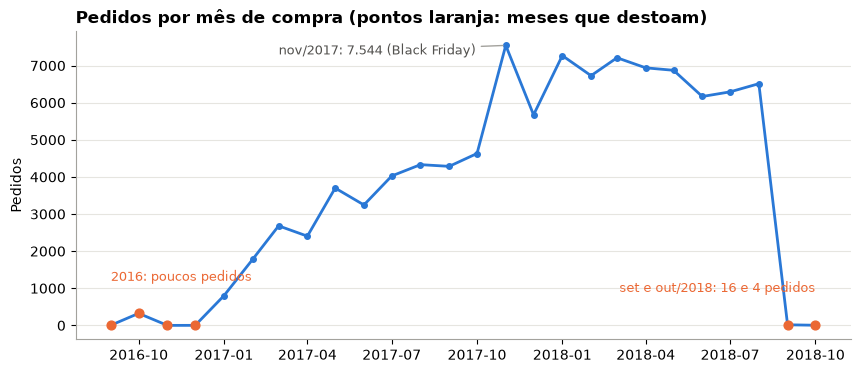

In [14]:
mes_compra = orders['order_purchase_timestamp'].dt.to_period('M')
pedidos_por_mes = orders.groupby(mes_compra).size()
print(pedidos_por_mes)

serie = pedidos_por_mes.reindex(pd.period_range('2016-09', '2018-10', freq='M'), fill_value=0)
x = serie.index.to_timestamp()
pontas = (serie.index < pd.Period('2017-01')) | (serie.index > pd.Period('2018-08'))

plt.figure()
plt.plot(x, serie.values, color=AZUL, linewidth=2, marker='o', markersize=4)
plt.scatter(x[pontas], serie.values[pontas], color=LARANJA, s=40, zorder=3)
plt.annotate('nov/2017: 7.544 (Black Friday)', xy=(pd.Timestamp('2017-11-01'), 7544),
             xytext=(pd.Timestamp('2017-03-01'), 7300), fontsize=9, color='#52514e',
             arrowprops=dict(arrowstyle='-', color='#a3a29d'))
plt.text(pd.Timestamp('2018-10-01'), 900, 'set e out/2018: 16 e 4 pedidos', ha='right', fontsize=9, color=LARANJA)
plt.text(pd.Timestamp('2016-09-01'), 1200, '2016: poucos pedidos', fontsize=9, color=LARANJA)
plt.title('Pedidos por mês de compra (pontos laranja: meses que destoam)')
plt.ylabel('Pedidos')
plt.show()

- A base vai de **set/2016 a out/2018**, mas as pontas (em laranja no gráfico) destoam do resto:
  - 2016: 4 pedidos em setembro, 324 em outubro, **nenhum em novembro** e 1 em dezembro.
  - 2018: 6.512 pedidos em agosto, **16 em setembro e 4 em outubro**.
- Entre jan/2017 e ago/2018 o volume é contínuo, com crescimento e um pico em nov/2017 (7.544), mês da Black Friday.

A queda de 6.512 para 16 pedidos em um mês pede explicação. Duas hipóteses:

- **H5, queda real:** as vendas despencaram em set/2018.
- **H6, base incompleta:** a operação continuou, mas os pedidos desses meses não entraram na base.

Se a operação continuou normalmente, esses meses deveriam ter a mesma mistura de status de agosto: a maioria entregue ou a caminho. Comparo os status dos meses das pontas com `pd.crosstab()`, que conta pedidos por mês e status.

In [15]:
por_status = pd.crosstab(mes_compra, orders['order_status'])
pontas = ['2016-09', '2016-10', '2016-12', '2018-08', '2018-09', '2018-10']
por_status[por_status.index.astype(str).isin(pontas)]

order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable
order_purchase_timestamp,,,,,,,,
2016-09,0,2,0,1,0,0,1,0
2016-10,0,24,0,265,18,2,8,7
2016-12,0,0,0,1,0,0,0,0
2018-08,0,84,0,6351,23,0,47,7
2018-09,0,15,0,0,0,0,1,0
2018-10,0,4,0,0,0,0,0,0


- Ago/2018 se comporta como um mês normal: 6.351 entregues de 6.512.
- **Set e out/2018 não têm nenhum pedido entregue.** São 19 cancelados e 1 enviado.

Uma queda real de vendas reduziria o volume, mas não faria todos os pedidos restantes serem cancelados. Esse padrão favorece a H6.

Para testar a H6 por outro ângulo, uso a data prometida. A base registra eventos até 17/10/2018 (item 1.7). Se ela fosse uma foto completa da operação, deveria conter os pedidos que ainda estavam dentro do prazo nessa data: comprados nas semanas anteriores, com promessa posterior a 17/10. Antes, vejo o tamanho típico da promessa em ago/2018, último mês normal.

In [16]:
dias_prometidos = (orders['order_estimated_delivery_date'] - orders['order_purchase_timestamp']).dt.days
print('Prazo prometido mediano em ago/2018:', dias_prometidos[mes_compra == '2018-08'].median(), 'dias')
print('Pedidos por dia em ago/2018:', round(pedidos_por_mes[pd.Period('2018-08')] / 31))

dentro_do_prazo = orders[orders['order_estimated_delivery_date'] > data_foto]
dentro_do_prazo['order_status'].value_counts()

Prazo prometido mediano em ago/2018: 13.0 dias
Pedidos por dia em ago/2018: 210


order_status
canceled     4
delivered    2
Name: count, dtype: int64

- Em ago/2018 a Olist recebia cerca de **210 pedidos por dia**, com prazo prometido mediano de **13 dias**. Numa foto completa, seriam esperados **milhares de pedidos** com promessa posterior a 17/10.
- A base tem **6**, e nenhum em andamento: 4 cancelados e 2 entregues.

**Leitura:** a H5 (queda real) não explica a falta de pedidos a caminho. **A H6 é compatível com todos os testes:** a base pública parece ser uma **seleção** de pedidos, da qual ficaram de fora os pedidos recentes ainda não concluídos. Os dados não provam como a seleção foi feita, mas mostram que set e out/2018 não representam a operação.

O início em 2016 tem outro perfil: há pedidos entregues, mas o volume é irregular e há um mês sem nenhum pedido. É compatível com o começo da operação ou da coleta.

**Decisão:** toda análise no tempo usa o recorte de **jan/2017 a ago/2018**, 20 meses completos. A seleção da base é uma limitação a declarar no relatório: os dados descrevem os pedidos que a Olist publicou, não necessariamente toda a operação.

In [17]:
no_recorte = orders['order_purchase_timestamp'].between('2017-01-01', '2018-08-31 23:59:59')
print(f'Pedidos no recorte: {no_recorte.sum():,} ({no_recorte.mean() * 100:.2f}% da base)')

Pedidos no recorte: 99,092 (99.65% da base)


## 1.12 Resumo da tabela `orders`

| # | Verificação | O que os dados mostraram | Decisão |
|---|---|---|---|
| 1.1 | Volume | 99.441 pedidos, coerente com o enunciado | nenhuma |
| 1.4 | Unicidade | `order_id` não se repete | `order_id` é a chave do pedido |
| 1.4 | Cliente | `customer_id` também não se repete | hipótese: não identifica a pessoa (testar na tabela de clientes) |
| 1.6 | Vazios nas datas | explicados pelo status (H1); 23 entregues com data faltando (H2) | prazo só com `delivered` que tenham data de entrega |
| 1.7 | Pedidos parados | 1.729, todos com promessa vencida | travados, não em andamento; fora do cálculo de prazo |
| 1.8 | Fluxo do pedido | compatível com status e datas; fonte oficial da Olist | fluxo adotado como hipótese de trabalho |
| 1.9 | Hora da promessa | 100% em `00:00:00` | comparar entrega e promessa por dia |
| 1.10 | Ordem das datas | 1.382 pedidos com datas fora de ordem, todos envolvendo a postagem | prazo total de compra a entrega; esses pedidos fora da análise por etapa |
| 1.11 | Período | pontas incompletas; base parece seleção | recorte jan/2017 a ago/2018 (99,65% dos pedidos) |

Ainda em aberto: o motivo dos pedidos travados, a origem das datas de postagem (registro manual ou fuso) e se pedidos cancelados contam como venda.